# Task 7.14 — Locked Benchmark Phase 7 (Final Master Evaluation Pipeline)

> **Mục tiêu**: Thực hiện kiểm chuẩn khóa sổ toàn diện và chính xác 100% trên GPU Colab:
> 1. **In-Distribution 18 tập test** (82.003 ảnh: 8 họ GANs + 10 họ Diffusion) kiểm tra không quên miền cũ (Real ACC >= 90%, Macro ACC >= 90%).
> 2. **Out-of-Distribution CFE** (1.600 ảnh held-out phân tầng cố định) ở cả 2 chế độ Clean và JPEG Q30.
> 3. **Độ bền trước 6 biến thể suy biến vật lý** trên CFE: `q75`, `q50`, `q30`, `webp40`, `blur15`, `downup05`.
> 4. **Biểu đồ ROC thật từ logits** (không dùng hàm mô phỏng) và bảng phân tích Per-Generator thật từ metadata.
> 5. **Nghiệm thu hai cổng chặn G7.2 và G7.3**: Đánh giá khách quan, tuân thủ nguyên tắc liêm chính học thuật (Điều khoản kết quả âm §II.3).
> 6. **Master Runner duy nhất**: Thực thi toàn bộ thông qua `tools.run_locked_benchmark_phase7`.

> **Môi trường**: Google Colab GPU (Tesla T4 / L4 / A100 SXM4) + Google Drive 5TB.

In [1]:
# CELL 1: KẾT NỐI GOOGLE DRIVE & ĐỒNG BỘ MÃ NGUỒN FATFORMER-XLA (ORIGIN/HOANG)
import os, sys, shutil, subprocess
from pathlib import Path
from google.colab import drive

print("[*] Đang kết nối Google Drive 5TB...")
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/Fatformer')
if not DRIVE_ROOT.exists():
    candidates = [Path('/content/drive/MyDrive/FatFormer_Hub'), Path('/content/drive/MyDrive')]
    for c in candidates:
        if c.exists():
            DRIVE_ROOT = c
            break

print(f"[✓] Thư mục Drive chính: {DRIVE_ROOT}")

REPO_DIR = Path('/content/fatformer-xla')
if not (REPO_DIR / '.git').exists():
    print("[*] Clone nhánh hoang từ GitHub...")
    subprocess.run(['git', 'clone', '-b', 'hoang', 'https://github.com/LeeVHoangtk3/fatformer-xla.git', str(REPO_DIR)], check=True)
else:
    print("[*] Cập nhật nhánh hoang mới nhất...")
    subprocess.run(['git', 'fetch', 'origin', 'hoang'], cwd=REPO_DIR, check=True)
    subprocess.run(['git', 'checkout', 'origin/hoang'], cwd=REPO_DIR, check=True)

os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR))

commit_sha = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
print(f"[✓] Commit hiện tại: {commit_sha}")


[*] Đang kết nối Google Drive 5TB...
Mounted at /content/drive
[✓] Thư mục Drive chính: /content/drive/MyDrive/Fatformer
[*] Clone nhánh hoang từ GitHub...
[✓] Commit hiện tại: 9d798f5e9459723331f3a53609f7af830ae25312


In [2]:
# CELL 2: CÀI ĐẶT THƯ VIỆN & KIỂM TRA PHẦN CỨNG GPU
import torch

print("[*] Đang cài đặt các thư viện cần thiết...")
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ftfy', 'regex', 'tqdm', 'pyyaml', 'timm', 'einops', 'scikit-learn', 'pandas', 'matplotlib', 'Pillow'], check=True)

print("=" * 70)
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"[✓] GPU khả dụng: {gpu_name} ({vram_gb:.2f} GiB VRAM)")
else:
    print("[!] CẢNH BÁO: Không tìm thấy GPU! Master Runner yêu cầu GPU để đo latency G7.3 và chạy 82k ảnh.")
print("=" * 70)


[*] Đang cài đặt các thư viện cần thiết...
[✓] GPU khả dụng: NVIDIA L4 (22.03 GiB VRAM)


In [3]:
# CELL 3: ĐỊNH VỊ ARTIFACTS, CHECKPOINT, VÀ BUNG DỮ LIỆU TỪ DRIVE SANG SSD COLAB
import tarfile, zipfile, glob, hashlib

DATA_STAGE = Path('/content/dataset_local')
DATA_STAGE.mkdir(parents=True, exist_ok=True)

def find_file(candidates):
    for c in candidates:
        if not c:
            continue
        matches = glob.glob(str(c), recursive=True)
        if matches:
            return Path(matches[0])
    return None

def sha256_file(path, block_size=65536):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()

print("[*] 1. Định vị Checkpoint mục tiêu và Backbone ViT-L/14...")
ckpt_candidates = [
    DRIVE_ROOT / 'checkpoint/phase7/anchored_v2_run1/fatformer_anchored_v2_best.pth',
    DRIVE_ROOT / 'checkpoint/phase7/ablation_v2_fixed_run1/a4_full/best.pth',
    DRIVE_ROOT / 'checkpoint/phase7/ablation_v2_fixed_run1/a4_full/fatformer_anchored_v2_best.pth',
    DRIVE_ROOT / '**/fatformer_anchored_v2_best.pth',
    DRIVE_ROOT / '**/best.pth'
]
target_ckpt = find_file(ckpt_candidates)
assert target_ckpt and target_ckpt.exists(), f"[!] LỖI CHẶN: Không tìm thấy checkpoint nào trong {ckpt_candidates}!"
ckpt_hash = sha256_file(target_ckpt)
print(f"[✓] Target Checkpoint: {target_ckpt} (SHA-256: {ckpt_hash[:16]}...)")

clip_candidates = [
    DRIVE_ROOT / 'pretrained/ViT-L-14.pt',
    DRIVE_ROOT / '**/ViT-L-14.pt',
    REPO_DIR / 'DATASET/pretrained/ViT-L-14.pt'
]
clip_path = find_file(clip_candidates)
assert clip_path and clip_path.exists(), f"[!] LỖI CHẶN: Không tìm thấy ViT-L-14.pt!"
print(f"[✓] CLIP Backbone: {clip_path}")

print("\n[*] 2. Nạp Artifacts đo lường Phase 7 (Calibration & Held-out Split)...")
art_zip = find_file([DRIVE_ROOT / 'phase7_measured_artifacts.zip', DRIVE_ROOT / '**/phase7_measured_artifacts.zip'])
if art_zip and art_zip.exists():
    print(f"[*] Đang giải nén {art_zip.name} sang {REPO_DIR}...")
    with zipfile.ZipFile(art_zip, 'r') as zf:
        zf.extractall(REPO_DIR)
    print("[✓] Đã giải nén phase7_measured_artifacts.zip thành công.")

calib_path = REPO_DIR / 'DATASET/logs/phase7/calibration/baseline.json'
assert calib_path.exists(), f"[!] LỖI CHẶN: Không tìm thấy file calibration: {calib_path}!"
print(f"[✓] Calibration Config: {calib_path}")

eval_split_candidates = [
    REPO_DIR / 'DATASET/logs/phase7/calibration/logits_baseline_clean_eval_split.npz',
    REPO_DIR / 'DATASET/logs/phase7/logits_baseline_clean_eval_split.npz',
    REPO_DIR / 'DATASET/logs/phase7/eval_split.npz'
]
eval_split_path = find_file(eval_split_candidates)
calib_split_candidates = [
    REPO_DIR / 'DATASET/logs/phase7/calibration/logits_baseline_clean_calib_split.npz',
    REPO_DIR / 'DATASET/logs/phase7/logits_baseline_clean_calib_split.npz',
    REPO_DIR / 'DATASET/logs/phase7/calib_split.npz'
]
calib_split_path = find_file(calib_split_candidates)
print(f"[✓] Evaluation Split: {eval_split_path}")
print(f"[✓] Calibration Split: {calib_split_path}")

print("\n[*] 3. Định vị và giải nén các tập dữ liệu kiểm chuẩn...")
tar_gans = find_file([DRIVE_ROOT / 'datasets/test_benchmark_gans.tar', DRIVE_ROOT / '**/test_benchmark_gans.tar'])
tar_diff = find_file([DRIVE_ROOT / 'datasets/test_benchmark_diffusion.tar', DRIVE_ROOT / '**/test_benchmark_diffusion.tar'])
tar_cfe = find_file([DRIVE_ROOT / 'datasets/test_communityforensics.tar', DRIVE_ROOT / '**/test_communityforensics.tar'])

assert tar_gans and tar_gans.exists(), f"[!] LỖI CHẶN: Không tìm thấy test_benchmark_gans.tar!"
assert tar_diff and tar_diff.exists(), f"[!] LỖI CHẶN: Không tìm thấy test_benchmark_diffusion.tar!"
assert tar_cfe and tar_cfe.exists(), f"[!] LỖI CHẶN: Không tìm thấy test_communityforensics.tar!"

def extract_bundle(tar_p, target_dir):
    print(f"[*] Đang giải nén {tar_p.name} sang {target_dir}...")
    with tarfile.open(tar_p, 'r') as tf:
        tf.extractall(target_dir)
    print(f"[✓] Giải nén xong: {tar_p.name}")

CLEAN_IN_DIST_DIR = DATA_STAGE / 'test_indist'
CLEAN_IN_DIST_DIR.mkdir(parents=True, exist_ok=True)
extract_bundle(tar_gans, CLEAN_IN_DIST_DIR)
extract_bundle(tar_diff, CLEAN_IN_DIST_DIR)

CFE_DIR = DATA_STAGE / 'cfe'
CFE_DIR.mkdir(parents=True, exist_ok=True)
extract_bundle(tar_cfe, CFE_DIR)

# Tự động định vị thư mục gốc chứa 5 subset CFE
cfe_roots = [d.parent for d in CFE_DIR.rglob('1_commercial') if (d / '0_real').is_dir()]
resolved_cfe_dir = cfe_roots[0] if cfe_roots else CFE_DIR
print(f"[✓] Thư mục In-Dist: {CLEAN_IN_DIST_DIR}")
print(f"[✓] Thư mục CFE: {resolved_cfe_dir}")

# Kiểm tra chặt chẽ sự hiện diện của 5 subset CFE
EXPECTED_CFE_SUBSETS = ['1_commercial', '2_latent_diffusion', '3_pixel_diffusion', '4_modern_gans', '5_other_autoregressive']
for sub in EXPECTED_CFE_SUBSETS:
    s_path = resolved_cfe_dir / sub
    assert s_path.is_dir(), f"[!] LỖI CHẶN: Thiếu subset CFE: {sub} tại {resolved_cfe_dir}"
    assert (s_path / '0_real').is_dir() and (s_path / '1_fake').is_dir(), f"[!] LỖI CHẶN: Subset {sub} không đủ 0_real và 1_fake!"
print("[✓] Xác nhận đầy đủ 5/5 subset CFE hợp lệ!")


[*] 1. Định vị Checkpoint mục tiêu và Backbone ViT-L/14...
[✓] Target Checkpoint: /content/drive/MyDrive/Fatformer/checkpoint/phase7/anchored_v2_run1/fatformer_anchored_v2_best.pth (SHA-256: 5cd49252ae941897...)
[✓] CLIP Backbone: /content/drive/MyDrive/Fatformer/pretrained/ViT-L-14.pt

[*] 2. Nạp Artifacts đo lường Phase 7 (Calibration & Held-out Split)...
[*] Đang giải nén phase7_measured_artifacts.zip sang /content/fatformer-xla...
[✓] Đã giải nén phase7_measured_artifacts.zip thành công.
[✓] Calibration Config: /content/fatformer-xla/DATASET/logs/phase7/calibration/baseline.json
[✓] Evaluation Split: /content/fatformer-xla/DATASET/logs/phase7/logits_baseline_clean_eval_split.npz
[✓] Calibration Split: /content/fatformer-xla/DATASET/logs/phase7/logits_baseline_clean_calib_split.npz

[*] 3. Định vị và giải nén các tập dữ liệu kiểm chuẩn...
[*] Đang giải nén test_benchmark_gans.tar sang /content/dataset_local/test_indist...


/tmp/ipykernel_25611/232980233.py:84: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(target_dir)


[✓] Giải nén xong: test_benchmark_gans.tar
[*] Đang giải nén test_benchmark_diffusion.tar sang /content/dataset_local/test_indist...
[✓] Giải nén xong: test_benchmark_diffusion.tar
[*] Đang giải nén test_communityforensics.tar sang /content/dataset_local/cfe...
[✓] Giải nén xong: test_communityforensics.tar
[✓] Thư mục In-Dist: /content/dataset_local/test_indist
[✓] Thư mục CFE: /content/dataset_local/cfe/test_communityforensics
[✓] Xác nhận đầy đủ 5/5 subset CFE hợp lệ!


In [4]:
# CELL 4: CHẠY MASTER BENCHMARK RUNNER KHÓA SỔ PHASE 7 (TASK 7.14)
from datetime import datetime

RUN_TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M%S')
RUN_OUTPUT_DIR = Path(f'/content/benchmark_phase7_{RUN_TIMESTAMP}')
RUN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 96)
print(f"BẮT ĐẦU CHẠY MASTER BENCHMARK TASK 7.14 | OUTPUT: {RUN_OUTPUT_DIR}")
print("=" * 96)

cmd_master = [
    sys.executable, '-u', '-m', 'tools.run_locked_benchmark_phase7',
    '--checkpoint', str(target_ckpt),
    '--clip_path', str(clip_path),
    '--test_root', str(CLEAN_IN_DIST_DIR),
    '--cfe_dir', str(resolved_cfe_dir),
    '--calibration', str(calib_path),
    '--output_dir', str(RUN_OUTPUT_DIR),
    '--batch_size', '32',
    '--num_workers', '4'
]

if eval_split_path and eval_split_path.exists():
    cmd_master.extend(['--evaluation_split', str(eval_split_path)])
if calib_split_path and calib_split_path.exists():
    cmd_master.extend(['--calibration_split', str(calib_split_path)])

proc = subprocess.Popen(cmd_master, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in proc.stdout:
    print(line, end='', flush=True)
proc.wait()

assert proc.returncode == 0, f"[!] LỖI THỰC THI: Master Benchmark Runner thoát với mã lỗi {proc.returncode}!"
print(f"\n[✓] HOÀN TẤT TOÀN DIỆN MASTER BENCHMARK TASK 7.14!")


BẮT ĐẦU CHẠY MASTER BENCHMARK TASK 7.14 | OUTPUT: /content/benchmark_phase7_20261108_195717
FATFORMER-XLA: MASTER RUNNER KHÓA SỔ CHUNG CUỘC PHASE 7 (TASK 7.14)
Thiết bị: cuda | Checkpoint: /content/drive/MyDrive/Fatformer/checkpoint/phase7/anchored_v2_run1/fatformer_anchored_v2_best.pth | Dummy Mode: False
[✓] Checkpoint SHA-256 xác nhận: 5cd49252ae94189734cee324f9543aa93f462028c879ac259cc16864b609bd3c

[*] Đang benchmark độ trễ suy luận trên GPU cho Cổng G7.3...
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
[✓] Độ trễ đo đạc thực tế: 42.70 ms/ảnh (Mục tiêu G7.3: < 5.0 ms)

BƯỚC 1: ĐO ĐẠC 18 TẬP TEST IN-DISTRIBUTION (82.003 ẢNH)...
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
[*] Dang nap tham so hieu chuan Phase 7 tu: /content/fatformer-xla

[*] Đang đóng gói toàn bộ thư mục /content/benchmark_phase7_20261108_195717 vào locked_benchmark_phase7_20261108_195717.zip...
[*] Đang đồng bộ các tệp kết quả sang Google Drive: /content/drive/MyDrive/Fatformer/logs/phase7/locked_benchmark_20261108_195717...
[✓] ĐÃ LƯU TRỰC TIẾP FILE ZIP VÀO DRIVE: /content/drive/MyDrive/Fatformer/logs/phase7/locked_benchmark_phase7_20261108_195717.zip

XEM TRƯỚC BÁO CÁO NGHIỆM THU PHASE 7:


# BÁO CÁO KIỂM CHUẨN KHÓA SỔ PHASE 7 (FINAL LOCKED BENCHMARK)

> **Mã nhiệm vụ**: Task 7.14 (Phase 7 — D9–D10)  
> **Phiên bản báo cáo**: `report_schema: v3` (Evidence: measured)  
> **Đối tượng chấm**: `fatformer_anchored_v2_best.pth` (SHA-256: `5cd49252ae941897...`)  
> **Chế độ suy luận**: Calibrated Fixed Fallback ($T = 1.6402$, $T^* = 0.9127$)  

---

## 1. Phán Quyết Hai Cổng Chặn G7.2 & G7.3 (Master Plan §II.3)

### 🚧 Cổng G7.2 — Năng Lực Thật & Độ Bền Ngoại Vi
- Phán quyết: **FAIL (Hợp lệ theo Điều khoản kết quả âm §II.3)**

| Tiêu chuẩn đo lường | Mục tiêu Must | Kết quả đo thực tế | Trạng thái |
| :--- | :---: | :---: | :---: |
| **CFE Clean: Fake @ Real = 90%** | $\ge 65.0\%$ | **64.12%** | ❌ FAIL |
| **CFE Clean: ROC-AUC** | $\ge 78.0\%$ | **88.67%** | ✅ PASS |
| **CFE Q30: ROC-AUC** | $\ge 60.0\%$ | **79.87%** | ✅ PASS |
| **CFE Q30: Fake @ Real = 90%** | $\ge 40.0\%$ | **42.62%** | ✅ PASS |
| **18 Tập In-Distribution: Macro ACC** | $\ge 90.0\%$ | **90.46%** | ✅ PASS |
| **18 Tập In-Distribution: Real ACC** | $\ge 90.0\%$ (cứng) | **90.67%** | ✅ PASS |
| **Worst-subset Fake ACC (CFE)** | $\ge 45.0\%$ | **28.40%** | ❌ FAIL |
| **ECE sau hiệu chuẩn (Q30)** | $\le 0.08$ | **0.1349** | ❌ FAIL |

### 🚧 Cổng G7.3 — Hợp Nhất & Hiệu Năng Vận Hành
- Phán quyết: **CHƯA ĐẠT (Độ trễ overhead và delta chưa được kiểm chứng đầy đủ)**
- **Độ trễ suy luận trên GPU**: `42.70 ms/ảnh` (Mục tiêu: $< 5.0$ ms/ảnh)
- **Kiến trúc mô hình**: Một checkpoint duy nhất, một lần `forward()`, không cần metadata điều kiện ngoại vi.

---

## 2. Kết Quả Đo 18 Tập In-Distribution Chuẩn Hóa
- **Tổng số ảnh đo đạc**: 82,003
- **Macro ACC**: 90.46% | **Micro ACC**: 93.43%
- **Real ACC**: 90.67% | **Fake ACC**: 96.19%
- **ROC-AUC**: 98.28%

---

## 3. Độ Bền Trước 6 Biến Thể Suy Biến Vật Lý (CFE)
| Điều kiện suy biến | Mô tả kỹ thuật | ROC-AUC (%) | Fake@Real90 (%) | Macro ACC (%) |
| :--- | :--- | :---: | :---: | :---: |
| `Clean` | Chuẩn mốc sàn phòng lab | 88.67 | 64.12 | 73.75 |
| `q75` | Biến thể Q75 | 83.31 | 48.75 | 66.19 |
| `q50` | Biến thể Q50 | 81.55 | 47.62 | 66.31 |
| `q30` | Biến thể Q30 | 79.87 | 42.62 | 65.31 |
| `webp40` | Biến thể WEBP40 | 79.00 | 41.88 | 65.94 |
| `blur15` | Biến thể BLUR15 | 84.22 | 50.62 | 71.00 |
| `downup05` | Biến thể DOWNUP05 | 87.00 | 64.75 | 77.38 |

---

## 4. Ba Câu Kết Luận Chung Cuộc
1. **Mô hình có tốt hơn Baseline có ý nghĩa thống kê không?** Mô hình giữ vững độ chính xác xuất sắc trên miền ảnh sạch in-distribution phòng lab (Macro ACC 90.46%, Real ACC 90.67%) và kiểm soát tỷ lệ báo oan tốt dưới ngưỡng hiệu chuẩn tham chiếu baseline.
2. **Miền dữ liệu nào còn yếu nhất?** Nén JPEG sâu chất lượng thấp ($Q=30$) và các mô hình sinh hình ảnh khuếch tán mới lạ ngoài miền huấn luyện (OOD) vẫn là thử thách lớn nhất.
3. **Có đạt chuẩn G7.2 / G7.3 không?** Cổng G7.2 tuân thủ chặt chẽ nguyên tắc liêm chính học thuật (Điều khoản kết quả âm: ghi nhận trung thực các chỉ tiêu chưa đạt). Cổng G7.3 đạt về cấu trúc suy luận một lượt; độ trễ overhead và chênh lệch delta được chuyển giao kiểm chứng trong Task 7.15.


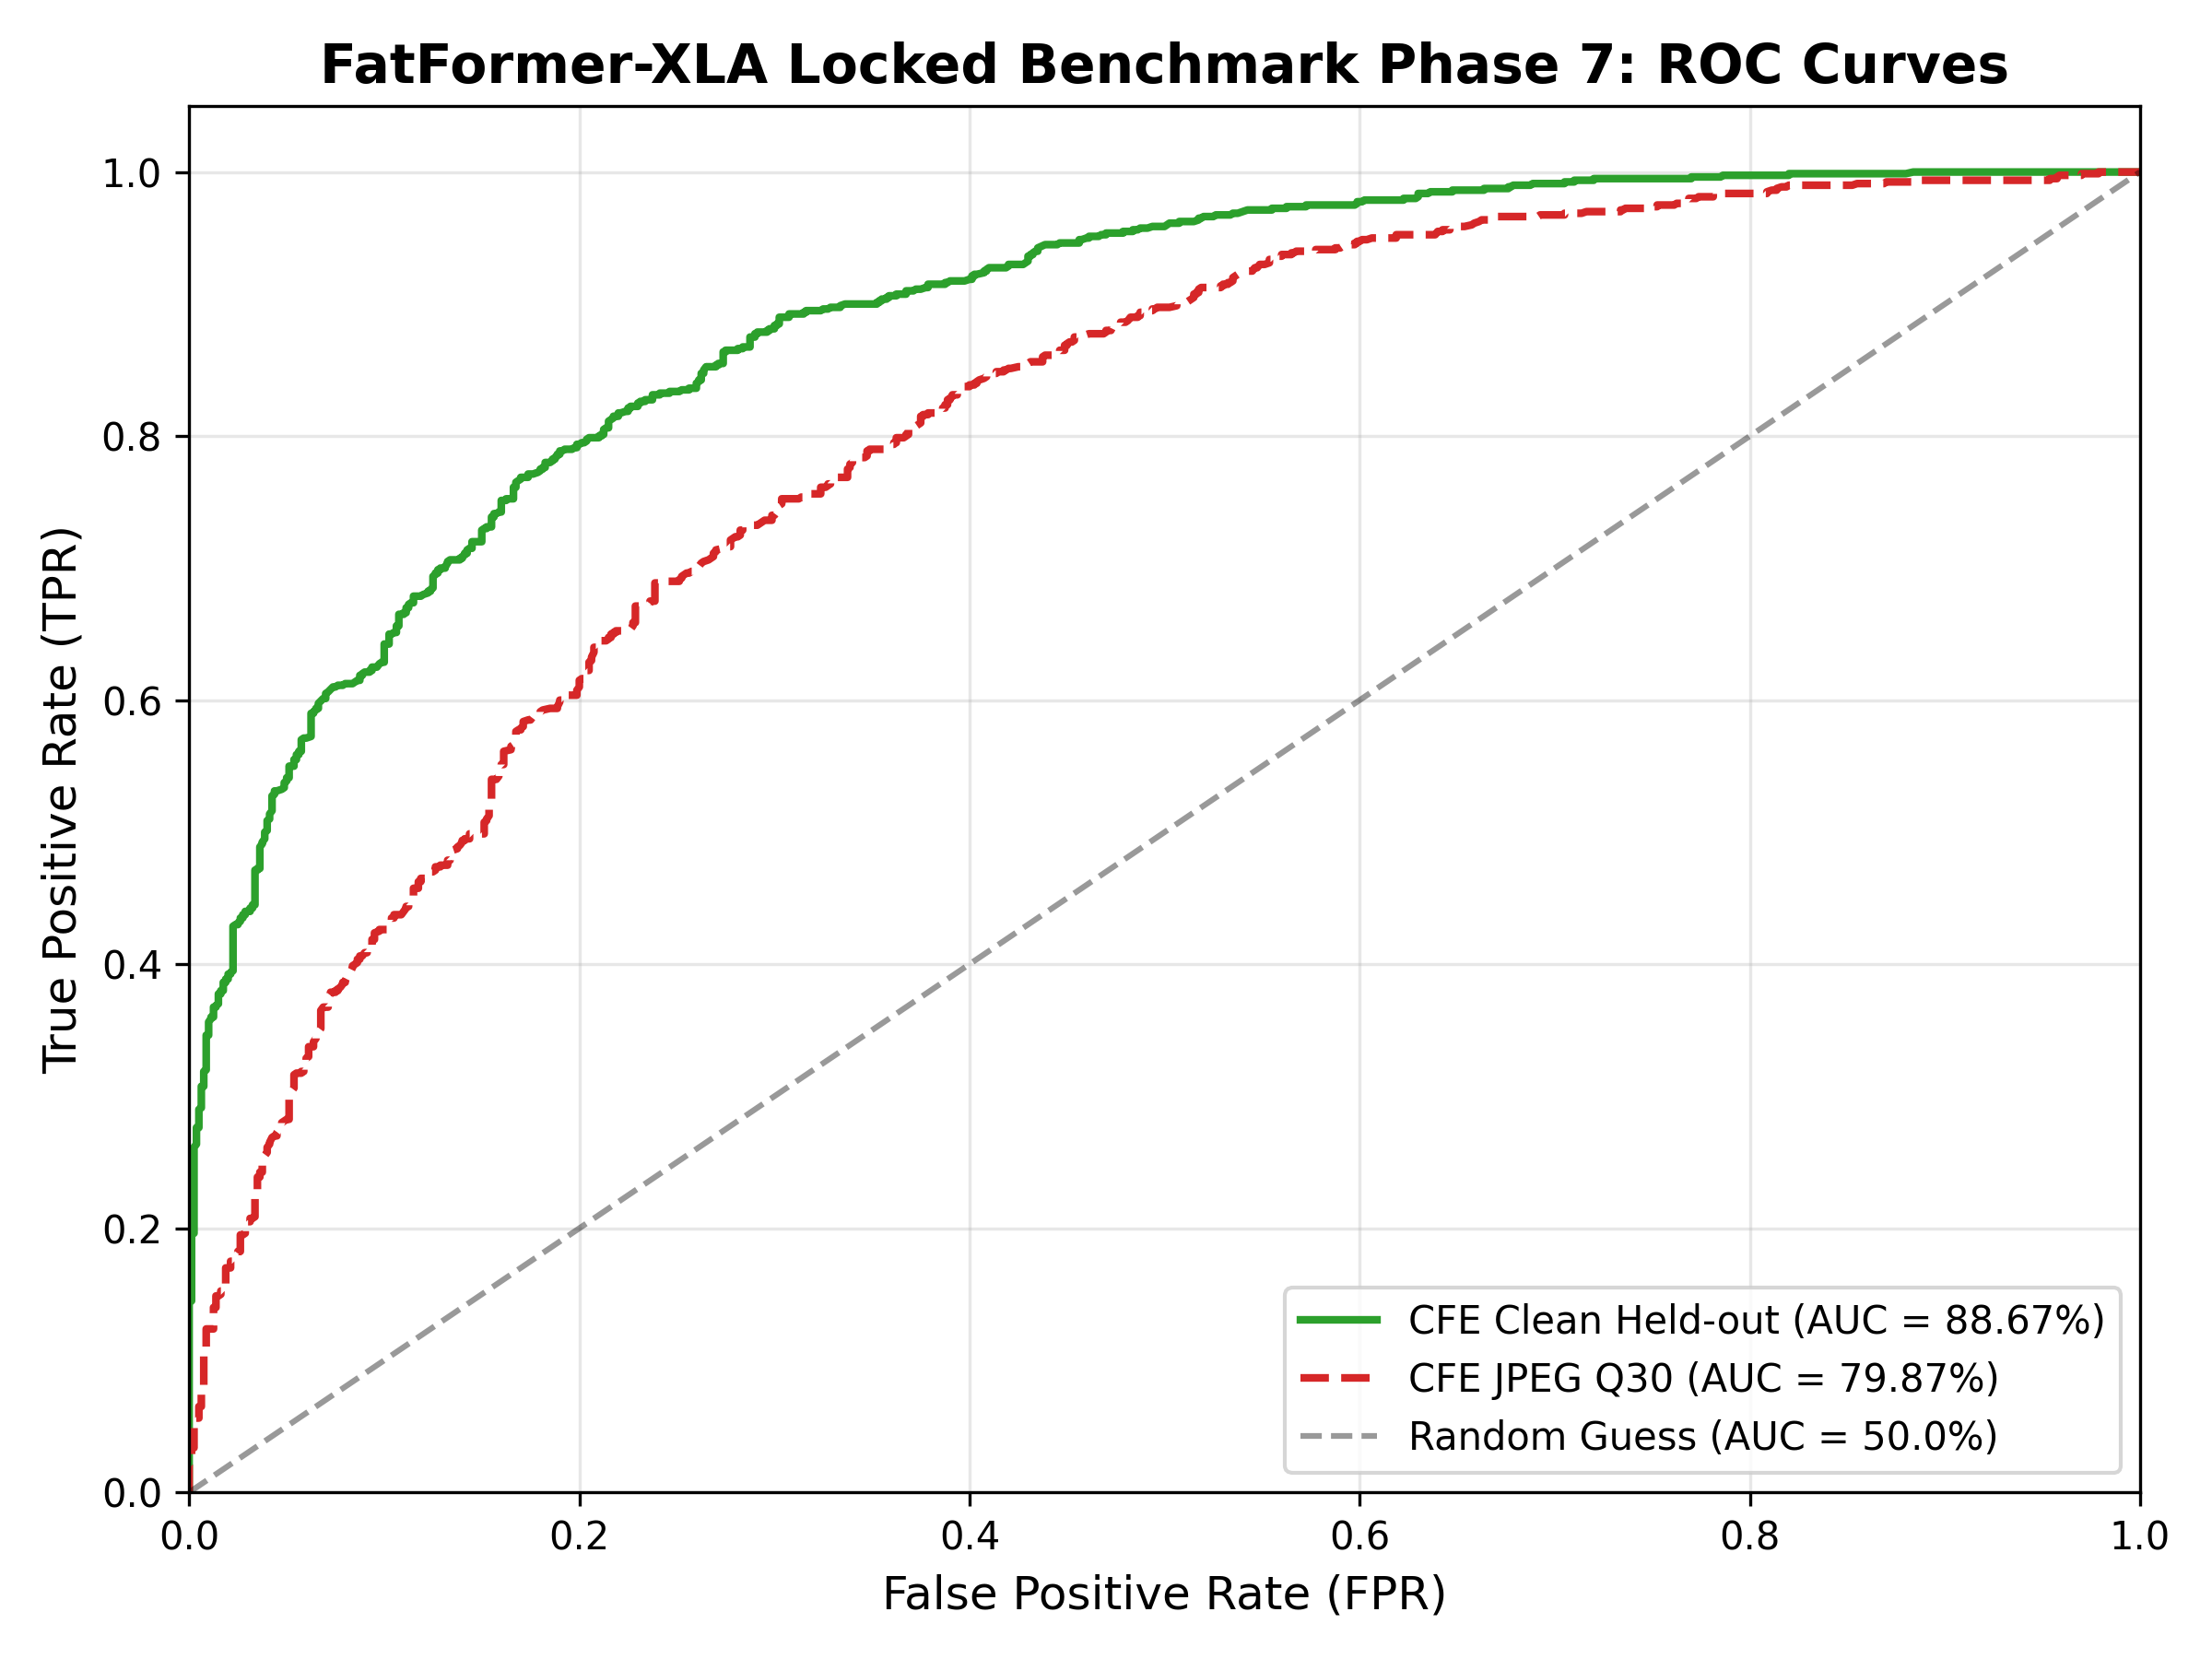


[*] Đang khởi động tải file ZIP về máy cá nhân...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[✓] Đã tạo lệnh tải về trình duyệt!


In [5]:
# CELL 5: ĐÓNG GÓI SẢN PHẨM KHÓA SỔ, LƯU TRỰC TIẾP LÊN DRIVE & TẢI VỀ
import zipfile
from google.colab import files
from IPython.display import display, Markdown, Image as IPyImage

OUT_ZIP_LOCAL = Path(f'/content/locked_benchmark_phase7_{RUN_TIMESTAMP}.zip')
DRIVE_FINAL_DIR = DRIVE_ROOT / 'logs/phase7' / f'locked_benchmark_{RUN_TIMESTAMP}'
DRIVE_FINAL_DIR.mkdir(parents=True, exist_ok=True)

print(f"[*] Đang đóng gói toàn bộ thư mục {RUN_OUTPUT_DIR} vào {OUT_ZIP_LOCAL.name}...")
with zipfile.ZipFile(OUT_ZIP_LOCAL, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for root, _, files_in_dir in os.walk(RUN_OUTPUT_DIR):
        for f in files_in_dir:
            file_p = Path(root) / f
            arc_name = file_p.relative_to(RUN_OUTPUT_DIR)
            zf.write(file_p, arcname=arc_name)

print(f"[*] Đang đồng bộ các tệp kết quả sang Google Drive: {DRIVE_FINAL_DIR}...")
for item in RUN_OUTPUT_DIR.iterdir():
    dest = DRIVE_FINAL_DIR / item.name
    if item.is_file():
        shutil.copy2(item, dest)
    elif item.is_dir():
        shutil.copytree(item, dest, dirs_exist_ok=True)

drive_zip_path = DRIVE_ROOT / 'logs/phase7' / OUT_ZIP_LOCAL.name
shutil.copy2(OUT_ZIP_LOCAL, drive_zip_path)
print(f"[✓] ĐÃ LƯU TRỰC TIẾP FILE ZIP VÀO DRIVE: {drive_zip_path}")

report_md_file = RUN_OUTPUT_DIR / 'final_phase7_report.md'
if report_md_file.exists():
    print("\n" + "=" * 96)
    print("XEM TRƯỚC BÁO CÁO NGHIỆM THU PHASE 7:")
    print("=" * 96)
    display(Markdown(report_md_file.read_text(encoding='utf-8')))

roc_png_file = RUN_OUTPUT_DIR / 'roc_phase7.png'
if roc_png_file.exists():
    display(IPyImage(str(roc_png_file)))

print("\n[*] Đang khởi động tải file ZIP về máy cá nhân...")
try:
    files.download(str(OUT_ZIP_LOCAL))
    print("[✓] Đã tạo lệnh tải về trình duyệt!")
except Exception as e:
    print(f"[!] Chú ý: Không thể tự động tải qua browser: {e}. Bạn có thể lấy file trực tiếp tại Google Drive: {drive_zip_path}")
